# Chinese dynasties
Counts individuals per Chinese dynasty (Shang → Qing) and the temporal precision of the dates behind their active life (first to last work, `cultura_enriched_v3.2`). An individual is attached to a dynasty when it is one of their active-life polities (`active_life_polity`).

In [1]:
import random
import tempfile

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.ticker import PercentFormatter
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'

apply_style()

## External data — none

## Chinese dynasty list

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='6GB'; SET threads=4; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql('''
    CREATE TEMP TABLE chinese_territories AS
    SELECT name                 AS name,
           territory.start_year AS start_year,
           territory.end_year   AS end_year
    FROM   polity, unnest(territories) AS unnested(territory)
    WHERE  list_contains(world, 'Chinese world')
''')

CHINESE_DYNASTIES = con.sql('''
    SELECT   name, MIN(start_year) AS first_year
    FROM     chinese_territories
    GROUP BY name
    ORDER BY first_year, name
''').pl()['name'].to_list()
assert len(set(CHINESE_DYNASTIES)) == len(CHINESE_DYNASTIES)
print(f'Chinese-world polities: {len(CHINESE_DYNASTIES)}')
print(CHINESE_DYNASTIES)

Chinese-world polities: 24
['Shang Dynasty', 'Zhou Dynasty', 'Qin Dynasty', 'Han Dynasty', 'Xin Dynasty', 'Western Jin', 'Northern Wei', 'Liu Song Dynasty', 'Liang Dynasty', 'Eastern Wei', 'Western Wei', 'Northern Qi', 'Chen Dynasty', 'Northern Zhou', 'Sui Dynasty', 'Tang Dynasty', 'Five Dynasties and Ten Kingdoms', 'Liao Dynasty', 'Northern Song', 'Western Xia', 'Southern Song', 'Yuan Dynasty', 'Ming Dynasty', 'Qing Dynasty']


## Load data
### Dynasty periods

In [3]:
dynasty_periods = con.sql("""
    SELECT   name            AS dynasty,
             MIN(start_year) AS from_year,
             MAX(end_year)   AS to_year
    FROM     chinese_territories
    GROUP BY name
""").pl()

assert dynasty_periods['dynasty'].is_unique
print('shape:', dynasty_periods.shape)
dynasty_periods.sort('from_year').head()

shape: (24, 3)


dynasty,from_year,to_year
str,i64,i64
"""Shang Dynasty""",-1600,-1001
"""Zhou Dynasty""",-1000,-751
"""Qin Dynasty""",-218,-209
"""Han Dynasty""",-202,237
"""Xin Dynasty""",6,29


### Individuals per dynasty

In [4]:
con.sql("""
    CREATE TEMP TABLE dynasty_matches AS
    SELECT DISTINCT entity.qid AS qid, polity_name AS dynasty
    FROM   (SELECT entity, unnest(list_transform(active_life_polity, stage_match -> stage_match.polity.name)) AS polity_name FROM individual_enriched)
    WHERE  list_contains($names, polity_name)
""", params={'names': CHINESE_DYNASTIES})

dynasty_individuals = con.sql("""
    SELECT dynasty_matches.*,
           individual_enriched.start_of_active_life.year      AS active_life_start,
           individual_enriched.end_of_active_life.year        AS active_life_end,
           individual_enriched.start_of_active_life.source    AS active_life_source,
           individual_enriched.start_of_active_life.precision AS work_precision,
           individual_enriched.birth_date.source              AS birth_source,
           individual_enriched.birth_date.precision           AS birth_precision,
           individual_enriched.birth_date.field_provenance['year'].rule ILIKE '%gives only%' AS birth_from_coarse,
           individual_enriched.death_date.precision           AS death_precision,
           coalesce(individual_enriched.birth_date.coarse_label, individual_enriched.death_date.coarse_label) AS coarse_label
    FROM   dynasty_matches
    JOIN   individual_enriched ON individual_enriched.entity.qid = dynasty_matches.qid
""").pl()

con.close()

assert dynasty_individuals.select('qid', 'dynasty').is_duplicated().sum() == 0
print('shape:', dynasty_individuals.shape)
print('distinct individuals:', dynasty_individuals['qid'].n_unique())
dynasty_individuals.head()

shape: (88410, 11)
distinct individuals: 87489


qid,dynasty,active_life_start,active_life_end,active_life_source,work_precision,birth_source,birth_precision,birth_from_coarse,death_precision,coarse_label
str,str,i64,i64,str,str,str,str,bool,str,str
"""Q100998547""","""Qing Dynasty""",1893,1909,"""estimated""","""year""","""wikidata""","""year""",null,"""year""",null
"""Q10107750""","""Southern Song""",1046,1069,"""estimated""","""year""","""wikidata""","""year""",null,"""year""",null
"""Q10108379""","""Liu Song Dynasty""",457,472,"""estimated""","""year""","""wikidata""","""decade""",null,"""year""",null
"""Q10112313""","""Tang Dynasty""",null,null,"""estimated from the century dat…","""century""","""wikidata""","""century""",null,"""century""","""9th AC"""
"""Q10114254""","""Qing Dynasty""",1655,1674,"""estimated""","""year""","""estimated""","""year""",false,"""year""",null


## Preprocessing
### Counts per dynasty

In [5]:
dynasty_counts = (
    dynasty_individuals
    .group_by('dynasty')
    .agg(
        pl.len().alias('all_individuals'),
        pl.col('active_life_start').is_not_null().sum().alias('with_active_life'),
    )
)

dynasty_summary = (
    pl.DataFrame({'dynasty': CHINESE_DYNASTIES})
    .join(dynasty_periods, on='dynasty', how='left')
    .join(dynasty_counts, on='dynasty', how='left')
    .with_columns(pl.col('all_individuals', 'with_active_life').fill_null(0))
    .with_columns(
        (pl.col('all_individuals') - pl.col('with_active_life')).alias('missing_active_life'),
        (100 * pl.col('with_active_life') / pl.col('all_individuals')).round(1).alias('pct_with_active_life'),
    )
)

assert dynasty_summary['all_individuals'].sum() == dynasty_individuals.height
print('shape:', dynasty_summary.shape)
dynasty_summary.head(len(CHINESE_DYNASTIES))

shape: (24, 7)


dynasty,from_year,to_year,all_individuals,with_active_life,missing_active_life,pct_with_active_life
str,i64,i64,u32,u32,u32,f64
"""Shang Dynasty""",-1600,-1001,8,7,1,87.5
"""Zhou Dynasty""",-1000,-751,21,19,2,90.5
"""Qin Dynasty""",-218,-209,78,63,15,80.8
"""Han Dynasty""",-202,237,990,713,277,72.0
"""Xin Dynasty""",6,29,87,62,25,71.3
…,…,…,…,…,…,…
"""Western Xia""",990,1226,57,56,1,98.2
"""Southern Song""",1028,1278,6356,6310,46,99.3
"""Yuan Dynasty""",1294,1374,2707,2638,69,97.5


### Temporal precision
The precision of the date the active life is built on: the dated works, else the Wikidata birth, else the death an estimated birth comes from. Individuals with only a coarse date count as century and individuals with no date as no date; since active-life polities need a birth, a death and an active life, these two cases are now empty.

In [6]:
PRECISION_BUCKET = {'day': 'year', 'month': 'year', 'year': 'year', 'decade': 'decade',
                    'century': 'century', 'millennium': 'century', 'none': 'none'}
PRECISION_COLUMNS = ['year', 'decade', 'century', 'none']

source_precision = (
    pl.when(pl.col('active_life_source') == 'dated works and positions').then(pl.col('work_precision'))
      .when(pl.col('active_life_source').is_not_null() & (pl.col('birth_source') == 'wikidata')).then(pl.col('birth_precision'))
      .when(pl.col('active_life_source').is_not_null() & pl.col('birth_from_coarse')).then(pl.lit('century'))
      .when(pl.col('active_life_source').is_not_null()).then(pl.col('death_precision'))
      .when(pl.col('coarse_label').is_not_null()).then(pl.lit('century'))
      .otherwise(pl.lit('none'))
)

dynasty_precision = dynasty_individuals.with_columns(
    source_precision.replace_strict(PRECISION_BUCKET, default=None).alias('precision')
)
assert dynasty_precision['precision'].null_count() == 0
print(dynasty_precision.group_by('active_life_source', 'birth_source', 'precision').len().sort('len', descending=True).head(15))

precision_counts = (
    pl.DataFrame({'dynasty': CHINESE_DYNASTIES})
    .join(dynasty_precision.pivot(on='precision', index='dynasty', values='qid', aggregate_function='len'),
          on='dynasty', how='left')
)
for column in PRECISION_COLUMNS:
    if column not in precision_counts.columns:
        precision_counts = precision_counts.with_columns(pl.lit(0).alias(column))
precision_counts = (
    precision_counts
    .with_columns(pl.col(PRECISION_COLUMNS).fill_null(0).cast(pl.Int64))
    .with_columns(pl.sum_horizontal(PRECISION_COLUMNS).alias('total'))
    .select('dynasty', *PRECISION_COLUMNS, 'total')
)

assert precision_counts['total'].sum() == dynasty_individuals.height
print('shape:', precision_counts.shape)
precision_counts.head(len(CHINESE_DYNASTIES))

shape: (10, 4)
┌─────────────────────────────────┬──────────────┬───────────┬───────┐
│ active_life_source              ┆ birth_source ┆ precision ┆ len   │
│ ---                             ┆ ---          ┆ ---       ┆ ---   │
│ str                             ┆ str          ┆ str       ┆ u32   │
╞═════════════════════════════════╪══════════════╪═══════════╪═══════╡
│ estimated                       ┆ wikidata     ┆ year      ┆ 56748 │
│ estimated                       ┆ estimated    ┆ year      ┆ 28323 │
│ estimated from the century dat… ┆ wikidata     ┆ century   ┆ 1573  │
│ estimated                       ┆ estimated    ┆ century   ┆ 1005  │
│ dated works and positions       ┆ wikidata     ┆ year      ┆ 521   │
│ estimated                       ┆ wikidata     ┆ decade    ┆ 139   │
│ dated works and positions       ┆ estimated    ┆ year      ┆ 54    │
│ dated works and positions       ┆ wikidata     ┆ decade    ┆ 21    │
│ null                            ┆ null         ┆ century   ┆

dynasty,year,decade,century,none,total
str,i64,i64,i64,i64,i64
"""Shang Dynasty""",5,0,3,0,8
"""Zhou Dynasty""",16,0,5,0,21
"""Qin Dynasty""",46,2,30,0,78
"""Han Dynasty""",479,20,491,0,990
"""Xin Dynasty""",40,0,47,0,87
…,…,…,…,…,…
"""Western Xia""",50,0,7,0,57
"""Southern Song""",6259,7,90,0,6356
"""Yuan Dynasty""",2597,6,104,0,2707


## Figures
### Figure S4: Temporal precision per Chinese dynasty

#### Data plotted

In [7]:
precision_shares = precision_counts.with_columns(
    pl.when(pl.col('total') > 0).then(pl.col(column) / pl.col('total')).otherwise(0.0).alias(column)
    for column in PRECISION_COLUMNS
)
print('counts shape:', precision_counts.shape)
display(precision_counts)
print('shares shape:', precision_shares.shape)
precision_shares

counts shape: (24, 6)


dynasty,year,decade,century,none,total
str,i64,i64,i64,i64,i64
"""Shang Dynasty""",5,0,3,0,8
"""Zhou Dynasty""",16,0,5,0,21
"""Qin Dynasty""",46,2,30,0,78
"""Han Dynasty""",479,20,491,0,990
"""Xin Dynasty""",40,0,47,0,87
…,…,…,…,…,…
"""Western Xia""",50,0,7,0,57
"""Southern Song""",6259,7,90,0,6356
"""Yuan Dynasty""",2597,6,104,0,2707


shares shape: (24, 6)


dynasty,year,decade,century,none,total
str,f64,f64,f64,f64,i64
"""Shang Dynasty""",0.625,0.0,0.375,0.0,8
"""Zhou Dynasty""",0.761905,0.0,0.238095,0.0,21
"""Qin Dynasty""",0.589744,0.025641,0.384615,0.0,78
"""Han Dynasty""",0.483838,0.020202,0.49596,0.0,990
"""Xin Dynasty""",0.45977,0.0,0.54023,0.0,87
…,…,…,…,…,…
"""Western Xia""",0.877193,0.0,0.122807,0.0,57
"""Southern Song""",0.984739,0.001101,0.01416,0.0,6356
"""Yuan Dynasty""",0.959365,0.002216,0.038419,0.0,2707


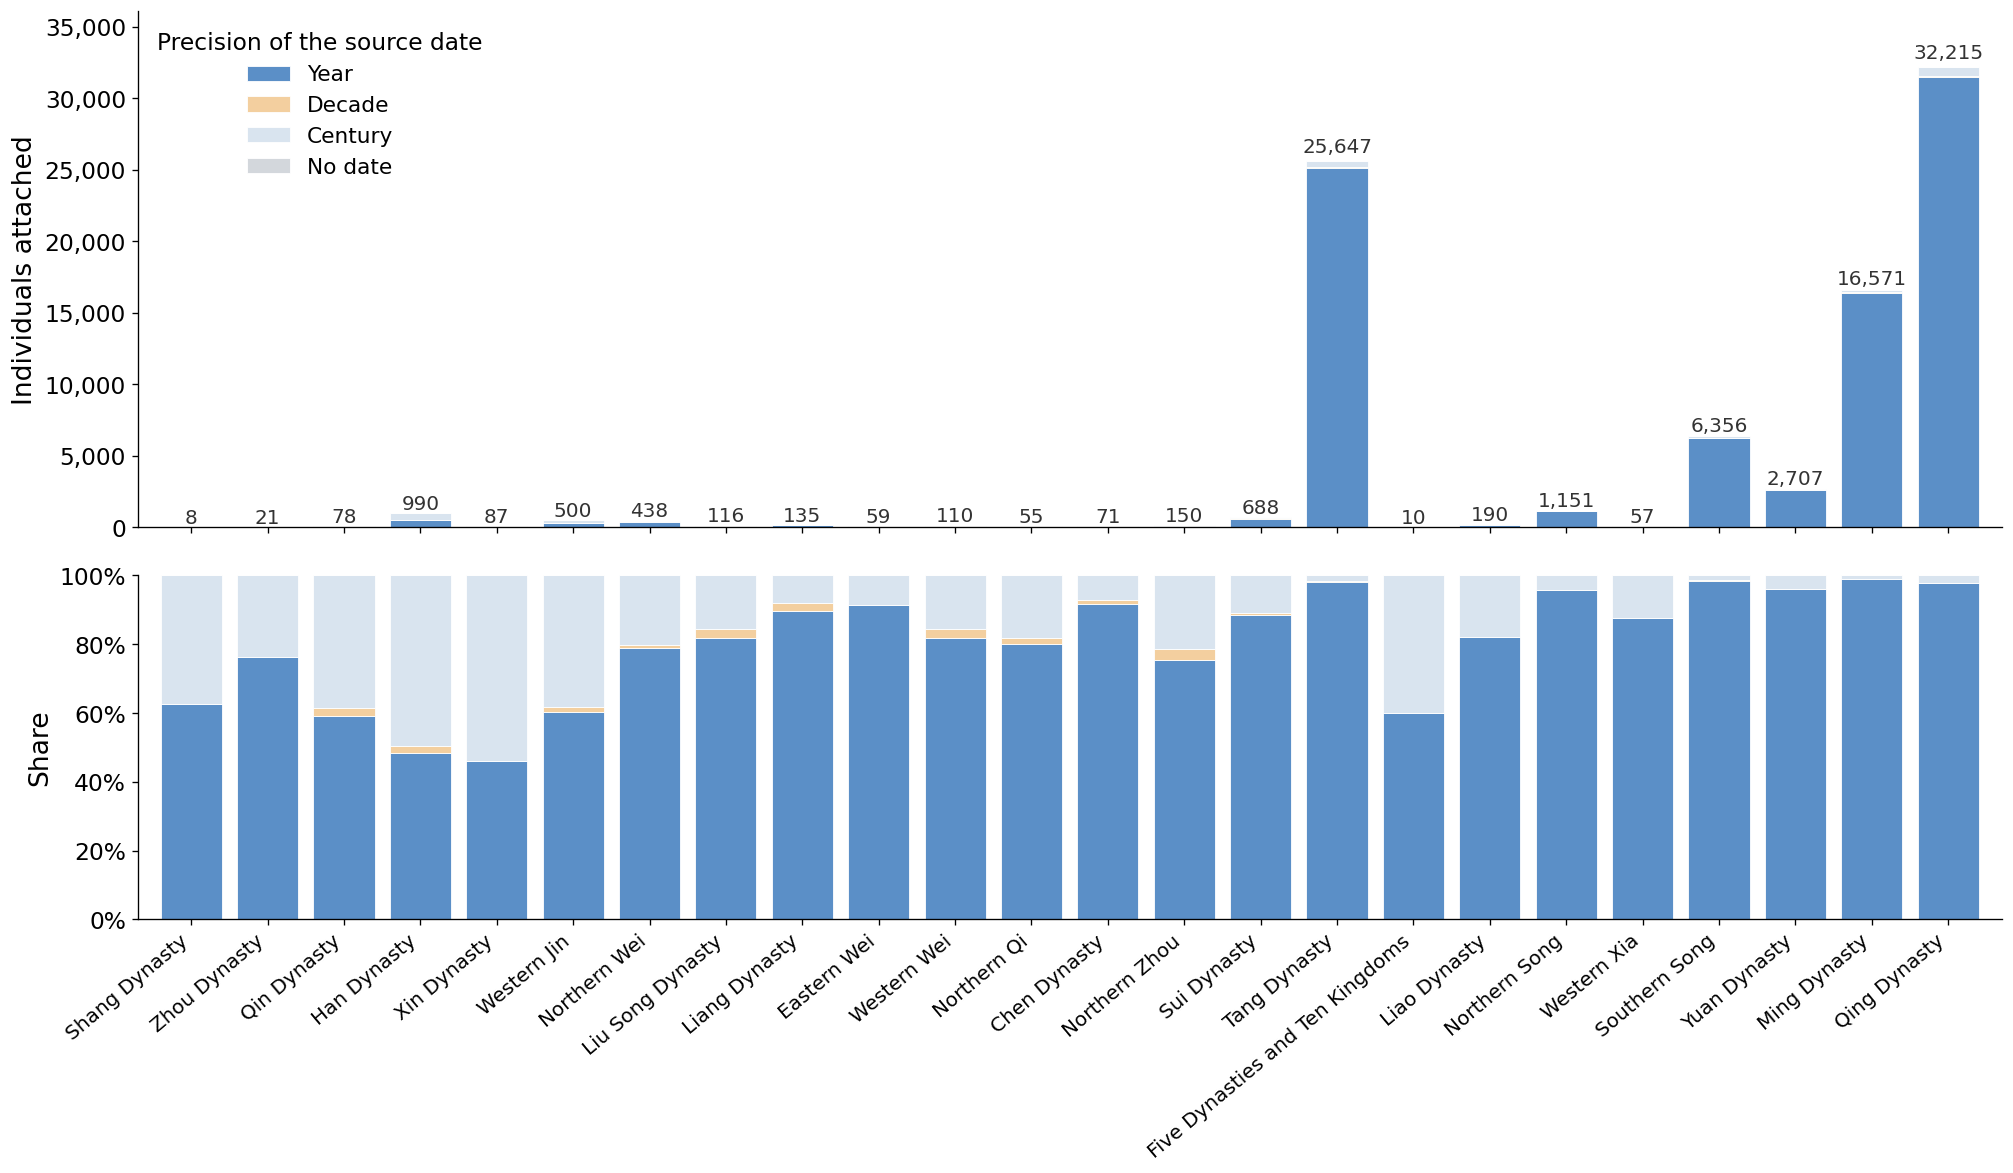

In [8]:
PRECISION_LABELS = {'year': 'Year', 'decade': 'Decade', 'century': 'Century', 'none': 'No date'}

dynasty_axis = precision_counts['dynasty'].to_list()
totals = precision_counts['total'].to_numpy().astype(float)
xs = np.arange(len(dynasty_axis))

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(17, 10), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

bottoms = np.zeros(len(xs))
for column in PRECISION_COLUMNS:
    counts = precision_counts[column].to_numpy().astype(float)
    ax_top.bar(xs, counts, bottom=bottoms, color=PRECISION_COLORS[column], edgecolor=BACKGROUND_COLOR,
               linewidth=0.5, label=PRECISION_LABELS[column])
    bottoms += counts
for x, total in zip(xs, totals):
    if total > 0:
        ax_top.text(x, total * 1.01, f'{int(total):,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE, color=TEXT)
ax_top.set_ylim(0, totals.max() * 1.12)
ax_top.yaxis.set_major_formatter(THOUSANDS)
ax_top.set_ylabel('Individuals attached')
ax_top.legend(loc='upper left', title='Precision of the source date')

shares = precision_shares.select(PRECISION_COLUMNS).to_numpy()
bottoms = np.zeros(len(xs))
for j, column in enumerate(PRECISION_COLUMNS):
    ax_bot.bar(xs, shares[:, j], bottom=bottoms, color=PRECISION_COLORS[column], edgecolor=BACKGROUND_COLOR, linewidth=0.5)
    bottoms += shares[:, j]
ax_bot.set_xticks(xs)
ax_bot.set_xticklabels(dynasty_axis, rotation=40, ha='right', fontsize=LONG_TICK_LABEL_FONTSIZE)
ax_bot.set_xlim(-0.7, len(xs) - 0.3)
ax_bot.set_ylim(0, 1)
ax_bot.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax_bot.set_ylabel('Share')

fig.tight_layout()
plt.show()